# Rician Fading Channel Statistics — Single Building Scenario

**Goal:** Compute per-receiver statistics using augmented Sionna RT.

| Statistic | Description |
|---|---|
| **RMS Delay Spread** | Power-weighted std-dev of multipath delays |
| **Rician K-Factor** | Ratio of LoS power to scattered power |
| **LoS Probability** | Fraction of realizations with a visible LoS path |

**Setup:**
- TX fixed at ~500 m – 1 km from the building  
- RX nominal positions randomly placed within **10 m** of the building face  
- **N realizations** per RX: each perturbed ±λ (a **2λ × 2λ** square)  
- `max_depth = 1` | Enabled: **LoS**, **Diffuse reflection**, **Diffraction**

## 1 · Environment Setup

In [20]:
import os
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit

%env DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"

env: DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"


## 2 · Imports

In [21]:
import numpy as np
import tensorflow as tf

import sionna
# Import or install Sionna
try:
    import sionna.rt
except ImportError as e:
    import os
    os.system("pip install sionna-rt")
    import sionna.rt

# Other imports
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from scipy import constants

no_preview = False # Toggle to False to use the preview widget
import mitsuba as mi
# mi.set_variant("cuda_rgb")
# Import relevant components from Sionna RT
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera,\
                      PathSolver, RadioMapSolver, subcarrier_frequencies, LambertianPattern

import gc
import pickle
import time

from scipy.special import i0e

## 3 · Configuration

> **⚠️ Update the values in this cell to match your scene before running.**

In [37]:

# ─── SCENE ────────────────────────────────────────────────────────────────────
# Path to your single-building XML scene file
SCENE_XML = "./better_building/building.xml"   # ← UPDATE THIS

# ─── RF ───────────────────────────────────────────────────────────────────────
FREQUENCY     = 11.7e9    # Carrier frequency [Hz]
TX_POWER_DBM  = 43       # TX transmit power [dBm]

# ─── GEOMETRY ─────────────────────────────────────────────────────────────────
#
#   Assumed layout (top view, looking down +Z):
#
#      TX (fixed)                      Building
#        ●───────────────────────────── [■■■■■■]  ─── RXs within 10 m ───►
#        |←──── TX_DISTANCE (~500 m) ──►|
#
#   TX is placed along the -X axis relative to the building face at X=0.
#   RX y-positions are scattered along the building face.
#

TX_DISTANCE       = 250.0   # [m]  Horizontal TX–building face distance
TX_HEIGHT         = 30.0    # [m]  TX height above ground

BUILDING_WIDTH   = 25.0     # [m]  Width of the building along the face (X-axis)
BUILDING_DEPTH   = 25.0     # [m]  Depth of the building (Y-axis)
BUILDING_CENTER_X = 0.0     # [m]  Building center along X (face at X=-12.5m)
BUILDING_CENTER_Y = 0.0     # [m]  Building center along Y

# RX sampling bounds near the building face
RX_MIN_OFFSET     = 0.5     # [m]  Min distance from building face (avoid clipping)
RX_MAX_OFFSET     = 10.0    # [m]  Max distance from building face
# RX_Y_HALF_RANGE   = 15.0    # [m]  Half-width along the building face (Y-axis)
RX_HEIGHT         = 0.5     # [m]  Receiver height above ground
# ─── Material properties ────────────────────────────────────────────────────────
# Concrete material properties (ITU-R P.2040-1)
a = 5.24; b = 0.0; c = 0.0462; d = 0.7822
SCATTERING_COEFF = 0.4  # Scattering
eta_r = a*(FREQUENCY/1e9)**b          # Relative permittivity (dielectric constant)
sigma = c*(FREQUENCY/1e9)**d       # Conductivity [S/m]

# ─── SIMULATION ───────────────────────────────────────────────────────────────
N_RX_POSITIONS    = 10_000     # Number of distinct nominal RX locations
# N_REALIZATIONS    = 1000     # Total realizations per nominal RX (position perturbations)

# ─── BATCHING ─────────────────────────────────────────────────────────────────
# Multiple receivers are placed in the scene simultaneously so the solver's
# shoot-and-bounce pass tests all targets in a single ray-tracing call.
# Realizations for each nominal RX position are grouped into batches of
# BATCH_SIZE, reducing total solver calls by a factor of BATCH_SIZE.
#
# samples_per_src and max_paths_per_src scale linearly with the actual batch
# size so that each receiver gets an equivalent ray budget to the single-RX
# baseline.
#
BATCH_SIZE           = 20       # RX receivers per solver call
BASE_SAMPLES_PER_SRC = 1_000_000  # Ray samples per source for ONE receiver
BASE_MAX_PATHS       = 1_000_000  # Max stored paths per source for ONE receiver
# → effective samples  = BASE_SAMPLES_PER_SRC × actual_batch_size  (auto-scaled)
# → effective max_paths = BASE_MAX_PATHS       × actual_batch_size  (auto-scaled)

RNG_SEED          = 42      # Global numpy RNG seed (reproducibility)

BEAMFORMING       = False   # Whether to use beamforming at the TX (omnidirectional if False)
BEAM_ANGLE     = np.arctan(50/TX_DISTANCE)   # TX beam angle in degrees (if BEAMFORMING=True)

# ─── OUTPUT ───────────────────────────────────────────────────────────────────
RESULTS_FILE = "./rician_building_results.pkl"
CHEKPOINT_FILE = "./rician_building_checkpoint.pkl"

# ──────────────────────────────────────────────────────────────────────────────
# Derived quantities
LAMBDA_C     = constants.c / FREQUENCY          # Wavelength [m]
PERTURB_HALF = LAMBDA_C                         # ±λ  → 2λ total square

TX_POS = [BUILDING_CENTER_X - (BUILDING_WIDTH/2) - TX_DISTANCE, BUILDING_CENTER_Y, TX_HEIGHT]

import math
n_batches_per_rx = math.ceil(N_RX_POSITIONS/ BATCH_SIZE)
total_solver_calls = N_RX_POSITIONS * n_batches_per_rx

print(f"Carrier frequency     : {FREQUENCY/1e9:.2f} GHz")
print(f"Wavelength            : {LAMBDA_C*100:.2f} cm")
print(f"Perturbation range    : ±{PERTURB_HALF*100:.2f} cm  (2λ × 2λ square)")
print(f"TX position           : {TX_POS}")
print(f"Scattering Coefficient: {SCATTERING_COEFF}")
print(f"eta_r (dielectric)     : {eta_r:.2f}")
print(f"sigma (conductivity)   : {sigma:.2e} S/m")

print(f"")
print(f"Batch size            : {BATCH_SIZE} receivers / call")
print(f"Batches per nominal RX: {n_batches_per_rx}")
# print(f"Total solver calls    : {total_solver_calls:,}  "
      # f"(vs {N_RX_POSITIONS * N_REALIZATIONS:,} single-RX calls)")
print(f"Speedup (approx)      : ~{BATCH_SIZE}×")
print(f"Samples per call      : {BASE_SAMPLES_PER_SRC} × batch_size  "
      f"(up to {BASE_SAMPLES_PER_SRC * BATCH_SIZE:,})")


Carrier frequency     : 11.70 GHz
Wavelength            : 2.56 cm
Perturbation range    : ±2.56 cm  (2λ × 2λ square)
TX position           : [-262.5, 0.0, 30.0]
Scattering Coefficient: 0.4
eta_r (dielectric)     : 5.24
sigma (conductivity)   : 3.16e-01 S/m

Batch size            : 20 receivers / call
Batches per nominal RX: 500
Speedup (approx)      : ~20×
Samples per call      : 1000000 × batch_size  (up to 20,000,000)


## 4 · Helper Functions

In [38]:
# ─── RMS Delay Spread ─────────────────────────────────────────────────────────

def rms_delay_spread(taus, amps):
    """
    Compute the power-weighted excess mean delay and RMS delay spread
    for a single CIR realisation.

    Parameters
    ----------
    taus : array-like [num_paths]   Path delays [s]
    amps : array-like [num_paths]   Complex (or real) amplitudes

    Returns
    -------
    tau_mean : float   Power-weighted mean excess delay [s]
    tau_rms  : float   RMS delay spread [s]
    """
    t = np.asarray(taus, dtype=float)
    a = np.asarray(amps)
    if len(t) == 0:
        return 0.0, 0.0
    P   = np.abs(a) ** 2
    den = np.sum(P)
    if den == 0:
        return 0.0, 0.0
    tau0 = t[0]
    dt   = t - tau0
    mu   = np.dot(dt, P) / den
    var  = np.dot((dt - mu) ** 2, P) / den
    return float(mu), float(np.sqrt(var))


# ─── Complex channel & power split ────────────────────────────────────────────

def complex_channel(taus, amps, freq):
    """h = Σ a_k · exp(−j 2π f τ_k)  →  returns a complex scalar."""
    a = np.asarray(amps, dtype=complex)
    t = np.asarray(taus, dtype=float)
    return np.sum(a * np.exp(-1j * 2 * np.pi * freq * t))


def split_los_scatter(taus, amps, inter_depth0, freq):
    """
    Split the CIR into LoS and scattered components.

    LoS paths are identified by interaction type == 0 (InteractionType.NONE)
    at the first interaction depth.

    Parameters
    ----------
    taus         : np.ndarray [num_paths]   Delays [s]
    amps         : np.ndarray [num_paths]   Complex amplitudes
    inter_depth0 : np.ndarray [num_paths]   Interaction type at depth-0 index
    freq         : float                    Carrier frequency [Hz]

    Returns
    -------
    P_los     : float  |h_LoS|²  [linear power]
    P_scatter : float  |h_scatter|²  [linear power]
    has_los   : bool   True if at least one LoS path exists
    """
    los_mask     = (inter_depth0 == 0)    # NONE → LoS
    scatter_mask = ~los_mask

    a  = np.asarray(amps, dtype=complex)
    t  = np.asarray(taus, dtype=float)
    ph = np.exp(-1j * 2 * np.pi * freq * t)

    h_tot     = np.sum(a     * ph)
    h_los     = np.sum(a[los_mask]     * ph[los_mask])     if np.any(los_mask)     else 0j
    h_scatter = np.sum(a[scatter_mask] * ph[scatter_mask]) if np.any(scatter_mask) else 0j

    return float(np.abs(h_los) ** 2), float(np.abs(h_scatter) ** 2), float(np.abs(h_tot)**2), bool(np.any(los_mask))


# ─── Rician K-Factor estimators ───────────────────────────────────────────────

def kfactor_from_powers(P_los_list, P_scatter_list):
    """
    Estimate Rician K from the ensemble mean power split:
        K = E[P_LoS] / E[P_scatter]
    Returns K (linear), or np.inf if scatter power is zero.
    """
    mean_los  = np.mean(P_los_list)
    mean_scat = np.mean(P_scatter_list)
    if mean_scat < 1e-300:
        return np.inf if mean_los > 0 else np.nan
    return float(mean_los / mean_scat)


# ─── Reference Rician PDF ─────────────────────────────────────────────────────

def rician_pdf(x, K, Omega):
    """Rician envelope PDF for K-factor K and total power Omega."""
    x = np.maximum(np.asarray(x, dtype=float), 1e-300)
    z = 2 * x * np.sqrt(K * (K + 1) / Omega)
    log_pdf = (
        np.log(2 * x * (K + 1) / Omega)
        - K
        - (K + 1) * x ** 2 / Omega
        + z
        + np.log(i0e(z))
    )
    return np.exp(log_pdf)


print("Helper functions defined.")

Helper functions defined.


## 5 · Scene Setup Function

In [39]:

def build_scene_batch(rx_positions_batch, tx_pos):
    """
    Load the single-building scene and configure one TX and a batch of RXs.

    All receivers share the same isotropic vertically-polarised antenna array.
    The TX is pointed toward the centroid of the receiver batch so that the
    orientation is reasonable for all targets even with isotropic patterns.

    Parameters
    ----------
    rx_positions_batch : list of [x, y, z]   Receiver positions [m]
                         Length = actual batch size (may be < BATCH_SIZE
                         for the last batch if N_REALIZATIONS % BATCH_SIZE != 0)
    tx_pos             : list/array [x, y, z] Transmitter position [m]

    Returns
    -------
    scene       : sionna.rt.Scene
    batch_size  : int   Number of receivers added (= len(rx_positions_batch))
    """
    scene = load_scene(SCENE_XML, merge_shapes=False)
    scene.frequency = FREQUENCY

    iso_array = PlanarArray(
        num_rows=1, num_cols=1,
        vertical_spacing=0.5, horizontal_spacing=0.5,
        pattern="iso", polarization="V"
    )
    scene.tx_array = iso_array
    scene.rx_array = iso_array

    tx = Transmitter(name="tx", position=tx_pos)
    scene.add(tx)
    tx.power_dbm = TX_POWER_DBM

    tx.look_at([0, 0, 0])

    for i, rx_pos in enumerate(rx_positions_batch):
        rx = Receiver(name=f"rx_{i}", position=rx_pos, orientation=[0., 0., 0.])
        scene.add(rx)

    return scene, len(rx_positions_batch)


print("Batch scene builder defined.")
print("  → Receiver tensors will have shape [batch_size, 1, 1, 1, num_paths]")


Batch scene builder defined.
  → Receiver tensors will have shape [batch_size, 1, 1, 1, num_paths]


## 6 · Sample Nominal RX Positions

Generated 10000 nominal RX positions.
  X range : -22.50 – 22.50 m
  Y range : -22.50 – 22.50 m
  Height  : 0.5 m (fixed)


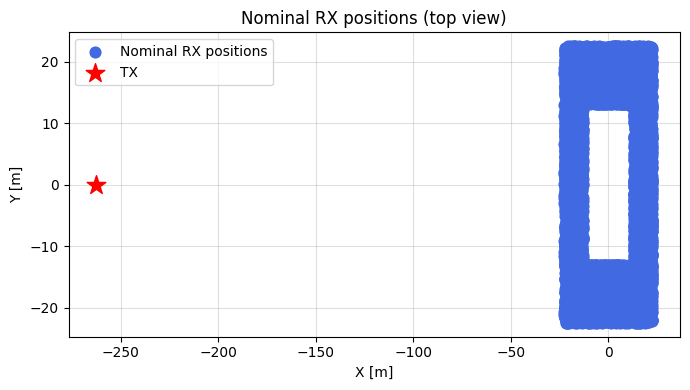

In [40]:
rng = np.random.default_rng(seed=RNG_SEED)

nominal_rx_positions = []
for i in range(N_RX_POSITIONS):
    # Distance from building face — uniform in [RX_MIN_OFFSET, RX_MAX_OFFSET]
    x = rng.uniform(-RX_MAX_OFFSET - BUILDING_DEPTH/2, BUILDING_DEPTH/2 + RX_MAX_OFFSET)
    y = rng.uniform(-RX_MAX_OFFSET - BUILDING_WIDTH/2, BUILDING_WIDTH/2 + RX_MAX_OFFSET)
    
    while np.abs(x) < RX_MIN_OFFSET + BUILDING_DEPTH/2 and np.abs(y) < RX_MIN_OFFSET + BUILDING_WIDTH/2:
        x = rng.uniform(-RX_MAX_OFFSET - BUILDING_DEPTH/2, BUILDING_DEPTH/2 + RX_MAX_OFFSET)
        y = rng.uniform(-RX_MAX_OFFSET - BUILDING_WIDTH/2, BUILDING_WIDTH/2 + RX_MAX_OFFSET)
    
    
    nominal_rx_positions.append([x, y, RX_HEIGHT])

nominal_rx = np.array(nominal_rx_positions)

print(f"Generated {N_RX_POSITIONS} nominal RX positions.")
print(f"  X range : {nominal_rx[:,0].min():.2f} – {nominal_rx[:,0].max():.2f} m")
print(f"  Y range : {nominal_rx[:,1].min():.2f} – {nominal_rx[:,1].max():.2f} m")
print(f"  Height  : {RX_HEIGHT:.1f} m (fixed)")

# Quick sanity plot
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(nominal_rx[:, 0], nominal_rx[:, 1],
           c='royalblue', s=60, zorder=3, label="Nominal RX positions")
# ax.axvline(BUILDING_FACE_X, color='k', linewidth=2, label="Building face (X=0)")
ax.scatter([TX_POS[0]], [TX_POS[1]], marker='*', c='red', s=200, zorder=4, label="TX")
ax.set_xlabel("X [m]"); ax.set_ylabel("Y [m]")
ax.set_title("Nominal RX positions (top view)")
ax.legend(); ax.grid(True, alpha=0.4)
plt.tight_layout(); plt.show()

with open("rx_positions.pkl", "wb") as _f:
        pickle.dump(nominal_rx, _f, protocol=pickle.HIGHEST_PROTOCOL)



## 7 · Main Simulation Loop

For each nominal RX position we run **N_REALIZATIONS** simulations,
each with the receiver perturbed within a **2λ × 2λ** square.  
Enabled propagation mechanisms: **LoS · Diffuse reflection · Diffraction**  
`max_depth = 1`

In [8]:
# batch 
with open("./rician_building_results_checkpoint.pkl", "rb") as f:
    checkpoint = pickle.load(f)
print(f"Checkpoint loaded. Resuming from RX index {checkpoint['completed_rx']} / {checkpoint['total_rx']}")

# checkpoint = {
#         # Progress metadata
#         "completed_rx"         : rx_idx + 1,
#         "total_rx"             : N_RX_POSITIONS,
#         "n_realizations"       : N_REALIZATIONS,
#         "frequency"            : FREQUENCY,
#         "tx_pos"               : TX_POS,
#         "tx_distance"          : TX_DISTANCE,
#         "batch_size"           : BATCH_SIZE,
#         "timestamp"            : time.strftime("%Y-%m-%dT%H:%M:%S"),
#         # Completed positions only (safe to resume from here)
#         "nominal_rx_positions" : nominal_rx_positions[: rx_idx + 1],
#         "K_power_ratio"        : all_K_power,
#         "K_moments"            : all_K_moments,
#         "tau_rms_mean_s"       : all_tau_rms,
#         "los_probability"      : all_p_los,
#         "raw_results"          : raw_results,
#     }

print(len(checkpoint["los_probability"]))

Checkpoint loaded. Resuming from RX index 610 / 1000
610


In [41]:
RESUME_FROM_CHECKPOINT = False
# checkpoint['completed_rx'] = 181
# print(len(checkpoint["raw_results"][205]['P_los_list']))
checkpoint = {}

In [42]:
# ─── Split nominal positions into batches ─────────────────────────────────────
n_pos       = len(nominal_rx_positions)
pos_batches = [
    nominal_rx_positions[i : i + BATCH_SIZE]
    for i in range(0, n_pos, BATCH_SIZE)
]
n_batches = len(pos_batches)

# ─── Result containers ────────────────────────────────────────────────────────
if RESUME_FROM_CHECKPOINT:
    completed_rx  = checkpoint['completed_rx']
    start_batch   = completed_rx // BATCH_SIZE   # safe: checkpoint always on batch boundary
    all_K_power   = checkpoint['K_power_ratio']
    all_pow_los   = checkpoint['P_los']
    all_pow_scat  = checkpoint['P_scat']
    # all_K_moments = checkpoint['K_moments']
    all_tau_rms   = checkpoint['tau_rms_mean_s']
    all_p_los     = checkpoint['los_probability']
    raw_results   = checkpoint['raw_results']
else:
    completed_rx  = 0
    start_batch   = 0
    all_K_power   = []
    all_pow_tot = []
    all_pow_los     = []
    all_pow_scat    = []
    all_tau_rms   = []
    all_p_los     = []
    raw_results   = []

solver      = PathSolver()
total_start = time.perf_counter()

for batch_idx, rx_batch in enumerate(pos_batches[start_batch:], start=start_batch):

    actual_bs = len(rx_batch)
    # print(f"\n── Batch {batch_idx+1:02d}/{n_batches}  ({actual_bs} RX positions) ──")
    batch_start = time.perf_counter()

    # ── Memory cleanup ─────────────────────────────────────────────────────
    for _n in ["paths", "amp_np", "tau_np", "inter_np", "scene"]:
        if _n in globals():
            del globals()[_n]
    gc.collect()
    drjit.flush_malloc_cache()
    drjit.eval()

    # ── Build scene — nominal positions, no perturbation ──────────────────
    scene, _ = build_scene_batch(rx_batch, TX_POS)
    mat = scene.get("itu_concrete")
    mat.scattering_coefficient = SCATTERING_COEFF
    mat.scattering_pattern     = LambertianPattern()
    mat.relative_permittivity  = eta_r
    mat.conductivity           = sigma

    seed = drjit.cuda.ad.UInt(int(rng.integers(1, 1_000_000)))

    paths = solver(
        scene                 = scene,
        max_depth             = 1,
        los                   = True,
        specular_reflection   = False,
        diffuse_reflection    = True,
        refraction            = False,
        diffraction           = True,
        edge_diffraction      = False,
        synthetic_array       = False,
        beamforming           = BEAMFORMING,
        beam_angle            = BEAM_ANGLE,
        max_num_paths_per_src = BASE_MAX_PATHS       * actual_bs,
        samples_per_src       = BASE_SAMPLES_PER_SRC * actual_bs,
        seed                  = seed,
    )

    amp_np,  tau_np  = paths.cir(normalize_delays=False, out_type="numpy")
    inter_np         = paths.interactions.numpy()

    # ── Per-receiver extraction ────────────────────────────────────────────
    for local_rx in range(actual_bs):
        rx_nom   = rx_batch[local_rx]

        t        = tau_np  [local_rx, 0, 0, 0, :]
        a        = amp_np  [local_rx, 0, 0, 0, :, 0]
        inter_d0 = inter_np[0, local_rx, 0, 0, 0, :]

        valid = np.abs(a) > 0.0
        t_v   = t       [valid]
        a_v   = a       [valid]
        id0_v = inter_d0[valid]

        has_los = bool(np.any(id0_v == 0))

        if len(t_v) > 0:
            P_los, P_scat,P_tot, _ = split_los_scatter(t_v, a_v, id0_v, FREQUENCY)
            _, ds             = rms_delay_spread(t_v, a_v)
            h_total           = complex_channel(t_v, a_v, FREQUENCY)
        else:
            P_los = P_scat = ds = 0.0
            h_total = 0j

        K_pr  = P_los / (P_scat + 1e-30)
        h_env = float(np.abs(h_total))

        all_K_power  .append(K_pr)
        all_pow_tot  .append(P_tot)
        all_pow_los  .append(P_los)
        all_pow_scat .append(P_scat)
        all_p_los    .append(1.0 if has_los else 0.0)
        all_tau_rms  .append(ds)
        if (completed_rx + 1) % 200 == 0:
            raw_results.append({
                "rx_nominal" : rx_nom,
                "taus"       : t_v.copy(),
                "amps"       : a_v.copy(),
                "inter_d0"   : id0_v.copy(),
                "P_tot"      : P_tot,
                "P_los"      : P_los,
                "P_scat"     : P_scat,
                "tau_rms_s"  : ds,
                "h_env"      : h_env,
                "has_los"    : has_los,
            })

        completed_rx += 1

    # ── Batch summary ─────────────────────────────────────────────────────
    K_batch   = all_K_power[-actual_bs:]
    K_dB_mean = float(np.mean([10 * np.log10(k + 1e-12) for k in K_batch]))
    p_los_pct = float(np.mean(all_p_los[-actual_bs:]) * 100)
    print(f"  done={completed_rx}/{N_RX_POSITIONS}  "
          f"K_mean={K_dB_mean:.1f} dB  "
          f"P(LoS)={p_los_pct:.0f}%  "
          f"elapsed={time.perf_counter()-batch_start:.1f}s")

    # ── Checkpoint (every 10 batches or on final batch) ────────────────────
    if (batch_idx + 1) % 50 == 0 or completed_rx == N_RX_POSITIONS:
        checkpoint = {
            "completed_rx"         : completed_rx,
            "total_rx"             : N_RX_POSITIONS,
            "frequency"            : FREQUENCY,
            "tx_pos"               : TX_POS,
            "tx_distance"          : TX_DISTANCE,
            "batch_size"           : BATCH_SIZE,
            "timestamp"            : time.strftime("%Y-%m-%dT%H:%M:%S"),
            "nominal_rx_positions" : nominal_rx_positions[:completed_rx],
            "K_power_ratio"        : all_K_power,
            "P_tot"                : all_pow_tot,
            "P_los"                : all_pow_los,
            "P_scat"               : all_pow_scat,
            "tau_rms_mean_s"       : all_tau_rms,
            "los_probability"      : all_p_los,
            "raw_results"          : raw_results,
        }
        print(f"  ✓ checkpoint saved  ({completed_rx}/{N_RX_POSITIONS})")

total_elapsed = time.perf_counter() - total_start
print(f"\n{'='*60}")
print(f"Simulation complete — {total_elapsed/3600:.2f} h  ({total_elapsed:.1f} s)")

  done=20/10000  K_mean=5.2 dB  P(LoS)=80%  elapsed=3.8s
  done=40/10000  K_mean=16.8 dB  P(LoS)=85%  elapsed=3.7s
  done=60/10000  K_mean=14.1 dB  P(LoS)=85%  elapsed=3.4s
  done=80/10000  K_mean=6.7 dB  P(LoS)=80%  elapsed=3.4s
  done=100/10000  K_mean=22.6 dB  P(LoS)=90%  elapsed=3.3s
  done=120/10000  K_mean=-24.5 dB  P(LoS)=60%  elapsed=3.3s
  done=140/10000  K_mean=21.5 dB  P(LoS)=90%  elapsed=3.3s
  done=160/10000  K_mean=8.1 dB  P(LoS)=80%  elapsed=3.4s
  done=180/10000  K_mean=12.5 dB  P(LoS)=85%  elapsed=3.3s
  done=200/10000  K_mean=-31.8 dB  P(LoS)=55%  elapsed=3.6s
  done=220/10000  K_mean=-4.2 dB  P(LoS)=75%  elapsed=3.3s
  done=240/10000  K_mean=0.8 dB  P(LoS)=75%  elapsed=3.3s
  done=260/10000  K_mean=29.5 dB  P(LoS)=95%  elapsed=3.2s
  done=280/10000  K_mean=-9.1 dB  P(LoS)=70%  elapsed=3.3s
  done=300/10000  K_mean=6.8 dB  P(LoS)=80%  elapsed=3.4s
  done=320/10000  K_mean=14.1 dB  P(LoS)=85%  elapsed=3.4s
  done=340/10000  K_mean=-9.6 dB  P(LoS)=70%  elapsed=3.3s
  do

## 8 · Save Results

In [43]:
results = {
    # Metadata
    "frequency"            : FREQUENCY,
    "tx_pos"               : TX_POS,
    "tx_distance"          : TX_DISTANCE,
    "n_rx_positions"       : N_RX_POSITIONS,
    # "n_realizations"       : N_REALIZATIONS,
    "perturb_half_m"       : PERTURB_HALF,
    "nominal_rx_positions" : nominal_rx_positions,
    # Per-RX statistics
    "K_power_ratio"        : all_K_power,
    "P_tot"                : all_pow_tot,
    "P_los"                : all_pow_los,
    "P_scat"               : all_pow_scat,
    "tau_rms_mean_s"       : all_tau_rms,
    "los_probability"      : all_p_los,
    # Raw per-realisation data
    "raw_results"          : raw_results,
}

with open(RESULTS_FILE, "wb") as f:
    pickle.dump(results, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Results saved → {RESULTS_FILE}")

Results saved → ./rician_building_results.pkl


In [44]:
with open("./rician_building_results.pkl", "rb") as f:
    results = pickle.load(f)

all_K_power  = results["K_power_ratio"]
all_pow_tot  = results["P_tot"]
all_pow_los  = results["P_los"]
all_pow_scat = results["P_scat"]
all_tau_rms  = results["tau_rms_mean_s"]
all_p_los    = results["los_probability"]
nominal_rx_positions = results["nominal_rx_positions"]


## 9 · Summary Statistics

In [45]:
K_pr   = np.array(all_K_power)
tau_ns = np.array(all_tau_rms) * 1e9    # → nanoseconds
has_los = np.array(all_p_los, dtype=bool)

K_pr_dB = 10 * np.log10(K_pr + 1e-12)

SEP = "═" * 62
print(SEP)
print(f"  CHANNEL STATISTICS  (N_RX = {N_RX_POSITIONS})")
print(f"  No perturbations — one CIR per nominal RX position")
print(SEP)

def _row(label, arr, fmt=".3f", unit=""):
    v = arr[np.isfinite(arr)]
    print(f"  {label:<28}  "
          f"mean={np.mean(v):{fmt}}  "
          f"median={np.median(v):{fmt}}  "
          f"std={np.std(v):{fmt}}  {unit}")

print("\n  Rician K-Factor (power ratio, per position):")
_row("  K [linear]", K_pr,    ".3f")
_row("  K [dB]",     K_pr_dB, ".2f", "dB")

print("\n  RMS Delay Spread:")
_row("  τ_rms [ns]", tau_ns, ".3f", "ns")

print("\n  LoS Indicator (binary per position):")
n_los  = int(np.sum(has_los))
n_nlos = N_RX_POSITIONS - n_los
print(f"  {'LoS positions':<28}  {n_los}  ({n_los/N_RX_POSITIONS*100:.1f} %)")
print(f"  {'NLOS positions':<28}  {n_nlos}  ({n_nlos/N_RX_POSITIONS*100:.1f} %)")

print(SEP)

══════════════════════════════════════════════════════════════
  CHANNEL STATISTICS  (N_RX = 10000)
  No perturbations — one CIR per nominal RX position
══════════════════════════════════════════════════════════════

  Rician K-Factor (power ratio, per position):
    K [linear]                  mean=36424.530  median=4032.541  std=381024.302  
    K [dB]                      mean=6.03  median=36.06  std=63.64  dB

  RMS Delay Spread:
    τ_rms [ns]                  mean=10.345  median=0.467  std=20.627  ns

  LoS Indicator (binary per position):
  LoS positions                 7990  (79.9 %)
  NLOS positions                2010  (20.1 %)
══════════════════════════════════════════════════════════════


## 10 · Visualisation

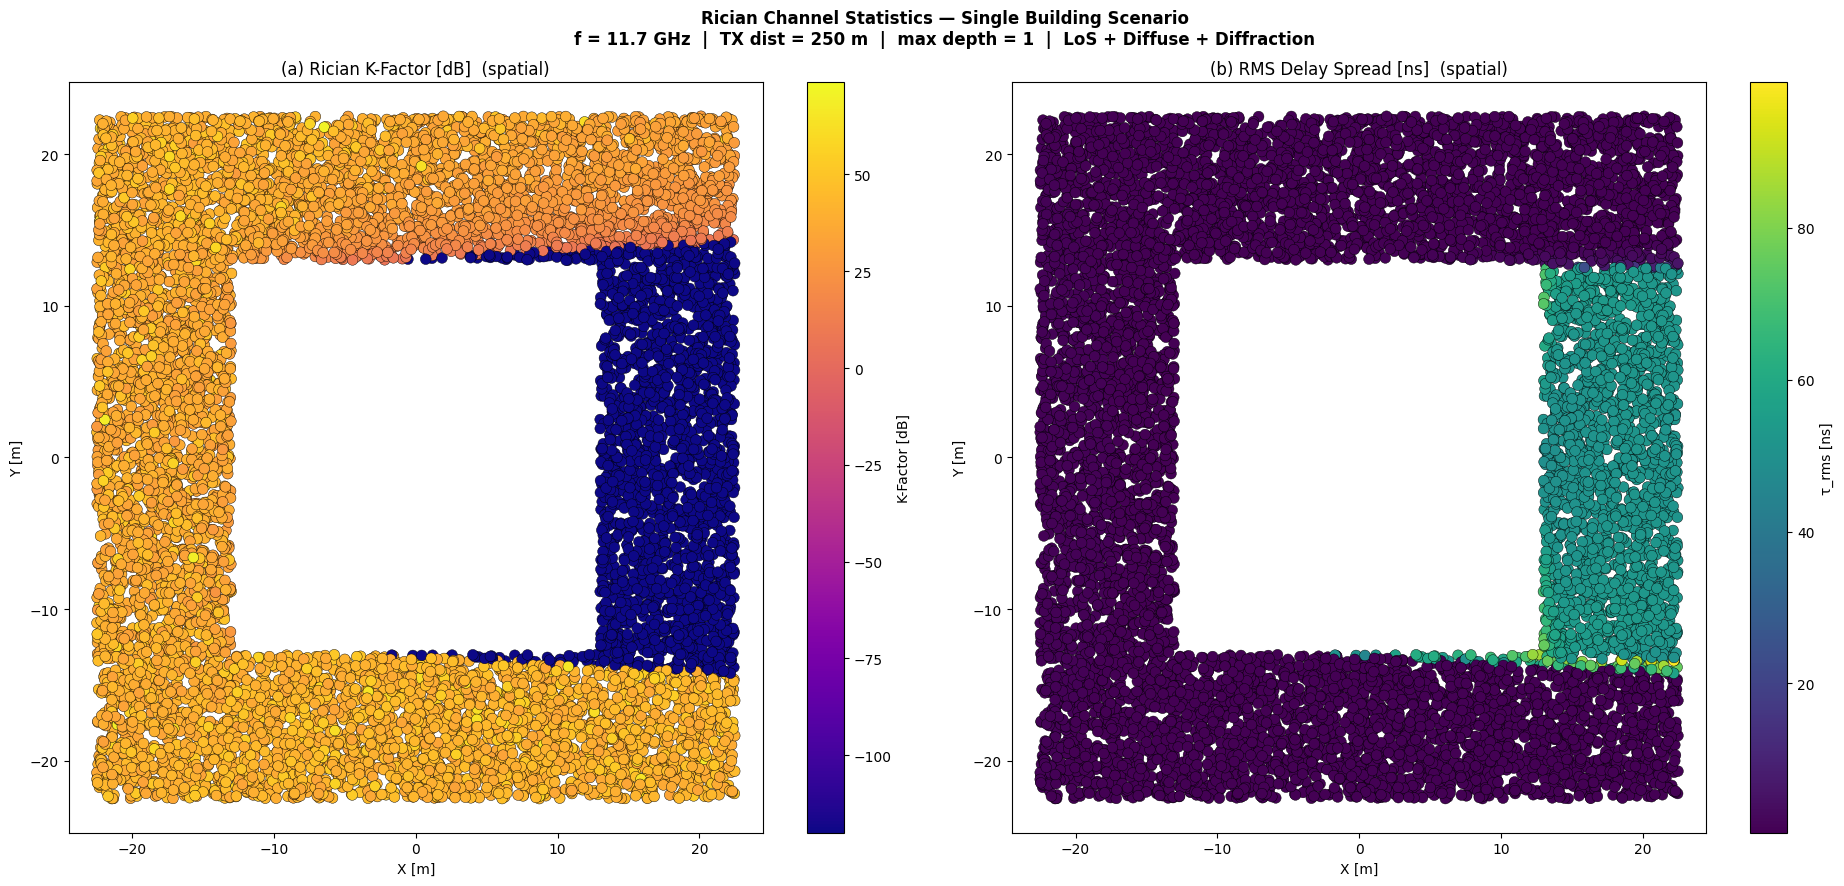

Figure saved → rician_building_stats.png


In [46]:
BUILDING_FACE_X = -12.5
# ─── Figure 1: Spatial maps + CDFs ───────────────────────────────────────────
rx_xy  = np.array(nominal_rx_positions)          # shape (N, 3)
rx_x   = rx_xy[:, 0]
rx_y   = rx_xy[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(19, 9))
fig.suptitle(
    f"Rician Channel Statistics — Single Building Scenario\n"
    f"f = {FREQUENCY/1e9:.1f} GHz  |  TX dist = {TX_DISTANCE:.0f} m  |  "
    f"max depth = 1  |  LoS + Diffuse + Diffraction",
    fontsize=12, fontweight='bold'
)

# # Helper: draw building face + TX marker on a spatial axes
# def _overlay_scene(ax):
#     # Building face (vertical line at x = BUILDING_FACE_X)
#     ylo, yhi = ax.get_ylim()
#     ax.axvline(BUILDING_FACE_X, color='k', linewidth=2, label='Building face')
#     ax.fill_betweenx([ylo, yhi],
#                      BUILDING_FACE_X - TX_DISTANCE,
#                      BUILDING_FACE_X,
#                      color='lightgray', alpha=0.25, label='Building side (−X)')
#     ax.set_ylim(ylo, yhi)   # restore after fill_betweenx
#     ax.annotate(f'TX\n({TX_POS[0]:.0f}, 0)',
#                 xy=(TX_POS[0], TX_POS[1]), fontsize=7,
#                 ha='center', color='red',
#                 bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='red', alpha=0.6))

# ── (a) Spatial map: K-Factor [dB] ───────────────────────────────────────────
ax = axes[0]
sc = ax.scatter(rx_x, rx_y, c=K_pr_dB, cmap='plasma',
                s=60, edgecolors='k', linewidths=0.3, zorder=3)
plt.colorbar(sc, ax=ax, label='K-Factor [dB]')
ax.set_xlim(BUILDING_FACE_X - 12, -BUILDING_FACE_X + 12)
# ax.axvline(BUILDING_FACE_X, color='k', linewidth=2, label='Building face')
ax.set_xlabel('X [m]'); ax.set_ylabel('Y [m]')
ax.set_title('(a) Rician K-Factor [dB]  (spatial)')
# ax.legend(fontsize=8, loc='upper right'); ax.grid(True, alpha=0.3)

# ── (b) Spatial map: RMS Delay Spread [ns] ────────────────────────────────────
ax = axes[1]
sc = ax.scatter(rx_x, rx_y, c=tau_ns, cmap='viridis',
                s=60, edgecolors='k', linewidths=0.3, zorder=3)
plt.colorbar(sc, ax=ax, label='τ_rms [ns]')
ax.set_xlim(BUILDING_FACE_X - 12, -BUILDING_FACE_X + 12)
# ax.axvline(BUILDING_FACE_X, color='k', linewidth=2, label='Building face')
ax.set_xlabel('X [m]'); ax.set_ylabel('Y [m]')
ax.set_title('(b) RMS Delay Spread [ns]  (spatial)')
# ax.legend(fontsize=8, loc='upper right'); ax.grid(True, alpha=0.3)

# # ── (c) CDF: K-Factor [dB] ───────────────────────────────────────────────────
# temp = np.where(has_los, 1.0, 0.0)
# los_mask = has_los
# ax = axes[1, 0]
# vals = K_pr_dB[np.isfinite(K_pr_dB)]
# sv   = np.sort(vals[los_mask])  # CDF only for positions with valid K (finite, i.e. non-inf)

# # cdf  = np.arange(1, len(sv) + 1) / len(sv)
# ax.hist(sv, bins=100, density=True, color='darkorchid', linewidth=2)
# # ax.axvline(np.nanmean(K_pr_dB), color='k', linestyle='--', linewidth=1.5,
# #            label=f'Mean  = {np.nanmean(K_pr_dB):.1f} dB')
# # ax.axvline(np.nanmedian(K_pr_dB), color='grey', linestyle=':', linewidth=1.5,
# #            label=f'Median = {np.nanmedian(K_pr_dB):.1f} dB')
# ax.set_xlabel('K-Factor [dB]'); ax.set_ylabel('CDF')
# ax.set_title('(c) K-Factor PDF')
# ax.legend(fontsize=9); ax.grid(True, alpha=0.35)

# # ── (d) CDF: RMS Delay Spread [ns] ────────────────────────────────────────────
# ax = axes[1, 1]
# sv_ds = np.sort(tau_ns)
# cdf_ds = np.arange(1, len(sv_ds) + 1) / len(sv_ds)
# ax.plot(sv_ds, cdf_ds, color='seagreen', linewidth=2)
# ax.axvline(np.mean(tau_ns), color='k', linestyle='--', linewidth=1.5,
#            label=f'Mean   = {np.mean(tau_ns):.3f} ns')
# ax.axvline(np.median(tau_ns), color='grey', linestyle=':', linewidth=1.5,
#            label=f'Median = {np.median(tau_ns):.3f} ns')
# ax.set_xlabel('RMS Delay Spread [ns]'); ax.set_ylabel('CDF')
# ax.set_title('(d) RMS Delay Spread CDF')
# ax.legend(fontsize=9); ax.grid(True, alpha=0.35)

plt.tight_layout()
plt.savefig("./rician_building_stats.png", dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved → rician_building_stats.png")


/tmp/ipykernel_3770602/1754856193.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8); ax.grid(True, alpha=0.3)


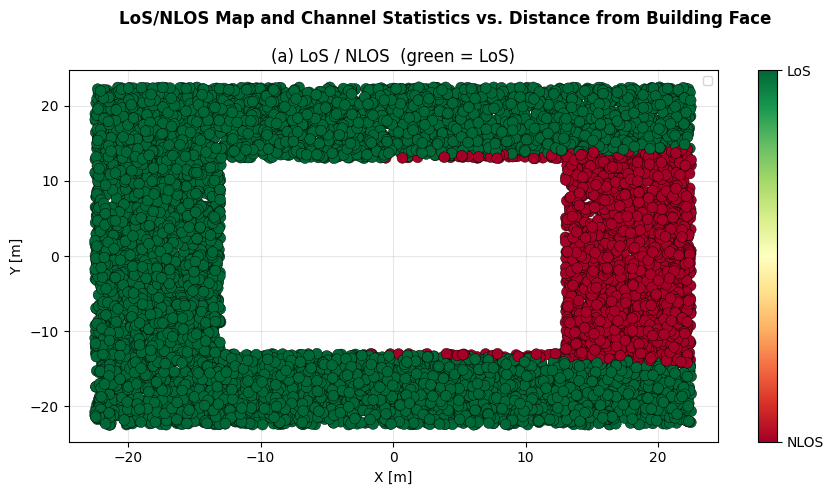

Figure saved → rician_building_los_dist.png


In [47]:
# ─── Figure 2: LoS spatial map + channel stats vs distance from building ──────
dist_from_face = rx_x - BUILDING_FACE_X    # [m], > 0 → receiver side

fig, axes = plt.subplots(1, 1, figsize=(9, 5))
fig.suptitle("LoS/NLOS Map and Channel Statistics vs. Distance from Building Face",
             fontsize=12, fontweight='bold')

# ── (a) LoS / NLOS binary spatial map ─────────────────────────────────────────
ax = axes
colors_los = np.where(has_los, 1.0, 0.0)
sc = ax.scatter(rx_x, rx_y, c=colors_los, cmap='RdYlGn',
                vmin=0, vmax=1, s=60, edgecolors='k', linewidths=0.3, zorder=3)
cbar = plt.colorbar(sc, ax=ax, ticks=[0, 1])
cbar.ax.set_yticklabels(['NLOS', 'LoS'])
# ax.axvline(BUILDING_FACE_X, color='k', linewidth=2, label='Building face')
ax.set_xlim(BUILDING_FACE_X - 12, -BUILDING_FACE_X + 12)
ax.set_xlabel('X [m]'); ax.set_ylabel('Y [m]')
ax.set_title('(a) LoS / NLOS  (green = LoS)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# # ── (b) K-Factor [dB] vs distance from building face ─────────────────────────
# ax = axes[1]
# los_mask  = has_los
# nlos_mask = ~has_los
# if np.any(los_mask):
#     ax.scatter(dist_from_face[los_mask],  K_pr_dB[los_mask],
#                color='seagreen',   s=50, edgecolors='k', linewidths=0.3,
#                label='LoS',  zorder=3)
# if np.any(nlos_mask):
#     ax.scatter(dist_from_face[nlos_mask], K_pr_dB[nlos_mask],
#                color='tomato', s=50, edgecolors='k', linewidths=0.3,
#                marker='^', label='NLOS', zorder=3)
# ax.axhline(np.nanmean(K_pr_dB), color='k', linestyle='--', linewidth=1.5,
#            label=f'Mean = {np.nanmean(K_pr_dB):.1f} dB')
# ax.set_xlabel('Distance from building face [m]')
# ax.set_ylabel('K-Factor [dB]')
# ax.set_title('(b) K-Factor vs. Distance')
# ax.legend(fontsize=8); ax.grid(True, alpha=0.35)

# # ── (c) RMS Delay Spread [ns] vs distance from building face ─────────────────
# ax = axes[2]
# if np.any(los_mask):
#     ax.scatter(dist_from_face[los_mask],  tau_ns[los_mask],
#                color='seagreen',   s=50, edgecolors='k', linewidths=0.3,
#                label='LoS',  zorder=3)
# if np.any(nlos_mask):
#     ax.scatter(dist_from_face[nlos_mask], tau_ns[nlos_mask],
#                color='tomato', s=50, edgecolors='k', linewidths=0.3,
#                marker='^', label='NLOS', zorder=3)
# ax.axhline(np.mean(tau_ns), color='k', linestyle='--', linewidth=1.5,
#            label=f'Mean = {np.mean(tau_ns):.3f} ns')
# ax.set_xlabel('Distance from building face [m]')
# ax.set_ylabel('τ_rms [ns]')
# ax.set_title('(c) RMS Delay Spread vs. Distance')
# ax.legend(fontsize=8); ax.grid(True, alpha=0.35)

plt.tight_layout()
plt.savefig("./rician_building_los_dist.png", dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved → rician_building_los_dist.png")


In [21]:
# ─── Per-RX breakdown table ──────────────────────────────────────────────────
MAX_ROWS = 50   # cap to avoid flooding output for large N_RX_POSITIONS

hdr = (f"{'#':>4} | {'X [m]':>7} | {'Y [m]':>7} | "
       f"{'K_PR [dB]':>10} | {'τ_rms [ns]':>11} | {'LoS':>5} | "
       f"{'P_los':>9} | {'P_scat':>9}")
print(hdr)
print("-" * len(hdr))

for i, rx in enumerate(nominal_rx_positions[:MAX_ROWS]):
    r = raw_results[i]
    p_los_val  = r.get('P_los',  float('nan'))
    p_scat_val = r.get('P_scat', float('nan'))
    los_str = "LoS " if bool(r.get('has_los', False)) else "NLOS"
    print(f"{i+1:>4} | {rx[0]:>7.2f} | {rx[1]:>7.2f} | "
          f"{K_pr_dB[i]:>10.2f} | {tau_ns[i]:>11.4f} | {los_str:>5} | "
          f"{p_los_val:>9.3e} | {p_scat_val:>9.3e}")

if N_RX_POSITIONS > MAX_ROWS:
    print(f"  ... ({N_RX_POSITIONS - MAX_ROWS} more rows not shown)")

   # |   X [m] |   Y [m] |  K_PR [dB] |  τ_rms [ns] |   LoS |     P_los |    P_scat
-----------------------------------------------------------------------------------
   1 |   16.14 |    8.88 |    -120.00 |     28.7027 |  LoS  | 1.479e-11 | 1.421e-16
   2 |  -18.26 |   21.40 |      47.96 |      0.3456 |  NLOS | 0.000e+00 | 9.908e-16
   3 |  -16.73 |   -2.23 |      45.86 |      0.3821 |  NLOS | 0.000e+00 | 7.891e-16
   4 |   -5.81 |   19.20 |      34.75 |      0.2192 |  LoS  | 1.646e-11 | 3.424e-16
   5 |    6.47 |   14.52 |      23.61 |      0.1902 |  LoS  | 1.459e-11 | 4.048e-16
   6 |    2.46 |  -19.63 |      45.29 |      0.2061 |  LoS  | 1.479e-11 | 1.895e-14
   7 |   14.74 |    5.92 |    -120.00 |     28.0487 |  LoS  | 1.591e-11 | 6.939e-18
   8 |   21.18 |   17.69 |      29.11 |      0.2364 |  LoS  | 1.595e-11 | 2.184e-16
   9 |   12.53 |  -13.74 |      49.02 |      0.2287 |  LoS  | 1.461e-11 | 5.663e-17
  10 |   -1.50 |  -20.53 |      51.05 |      0.2057 |  LoS  | 1.501e-11 | 2.

## 11 · Optional: Rician Envelope PDF vs. Empirical (per RX)

Uses the aggregate envelope samples from each RX position to compare the empirical distribution with the fitted Rician PDF.

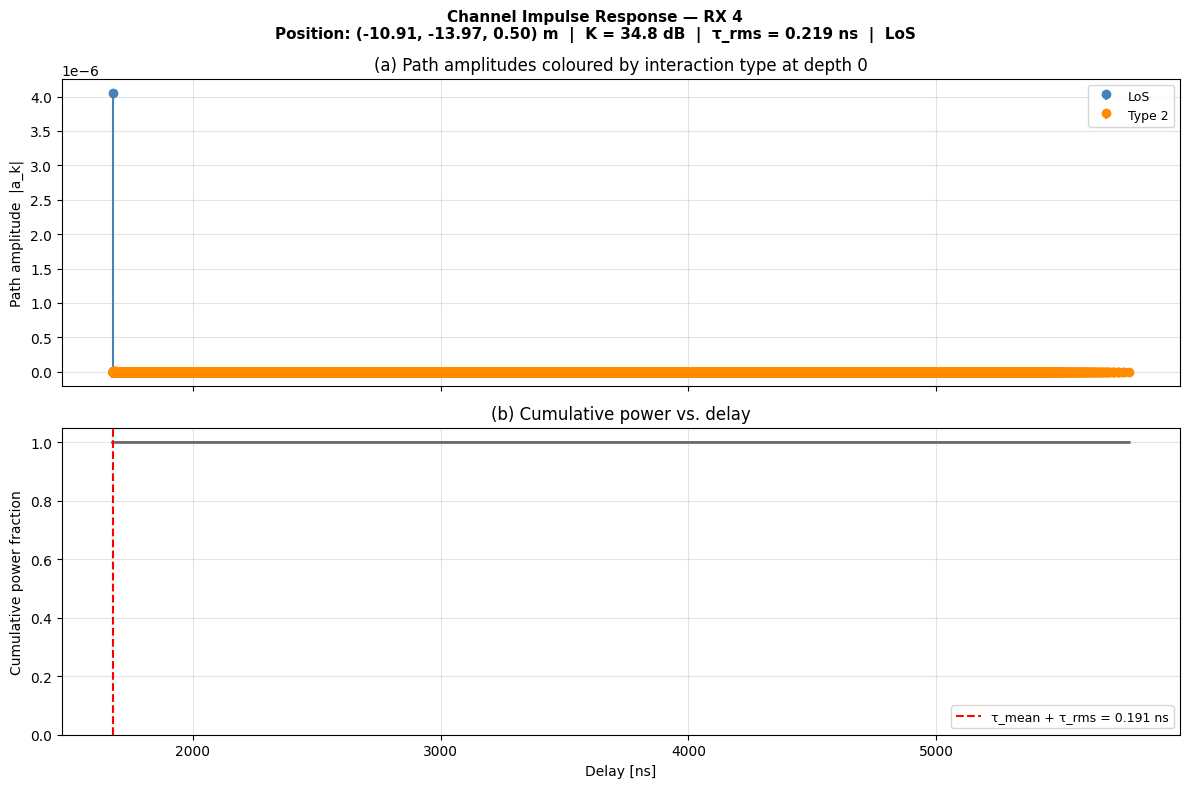

Figure saved → ./rician_building_cir_rx4.png
Total paths: 1228264  |  LoS paths: 1  |  Scatter/diff paths: 1228263


In [42]:
# ─── CIR Stem Plot — single position viewer ──────────────────────────────────
# Set CIR_RX_IDX to the 0-based index of the RX position you want to inspect.
# 'best_los'  → pick the position with the highest K-factor among LoS positions
# 'worst_los' → pick the position with the lowest  K-factor among LoS positions
# integer     → plot that specific index directly

CIR_RX_IDX = 3

# ── resolve index ─────────────────────────────────────────────────────────────
if CIR_RX_IDX == 'best_los':
    los_indices = np.where(has_los)[0]
    if len(los_indices) == 0:
        CIR_RX_IDX = int(np.argmax(K_pr))
    else:
        CIR_RX_IDX = int(los_indices[np.argmax(K_pr[los_indices])])
elif CIR_RX_IDX == 'worst_los':
    los_indices = np.where(has_los)[0]
    if len(los_indices) == 0:
        CIR_RX_IDX = int(np.argmin(K_pr))
    else:
        CIR_RX_IDX = int(los_indices[np.argmin(K_pr[los_indices])])

rx_idx = int(CIR_RX_IDX)
assert 0 <= rx_idx < len(raw_results), f"Index {rx_idx} out of range"

r         = raw_results[rx_idx]
taus_plot = np.asarray(r['taus'])   * 1e9         # → ns
amps_plot = np.abs(np.asarray(r['amps']))          # envelope
id0_plot  = np.asarray(r['inter_d0'], dtype=int)   # interaction type at depth 0
rx_nom    = r['rx_nominal']

# Colour by interaction type: 0=LoS (blue), else scatter/diffraction (orange/green)
unique_types = np.unique(id0_plot)
type_colors  = {0: 'steelblue'}                    # LoS
scatter_clrs = ['darkorange', 'seagreen', 'purple', 'crimson']
for k, t in enumerate(unique_types[unique_types != 0]):
    type_colors[int(t)] = scatter_clrs[k % len(scatter_clrs)]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
fig.suptitle(
    f"Channel Impulse Response — RX {rx_idx + 1}\n"
    f"Position: ({rx_nom[0]:.2f}, {rx_nom[1]:.2f}, {rx_nom[2]:.2f}) m  |  "
    f"K = {K_pr_dB[rx_idx]:.1f} dB  |  "
    f"τ_rms = {tau_ns[rx_idx]:.3f} ns  |  "
    f"{'LoS' if r['has_los'] else 'NLOS'}",
    fontsize=11, fontweight='bold'
)

# ── Top: amplitude stem ───────────────────────────────────────────────────────
ax = axes[0]
for itype in unique_types:
    mask = id0_plot == itype
    lbl  = "LoS" if itype == 0 else f"Type {itype}"
    clr  = type_colors[itype]
    markerline, stemlines, baseline = ax.stem(
        taus_plot[mask], amps_plot[mask],
        linefmt=clr, markerfmt='o', basefmt=' ',
        label=lbl
    )
    markerline.set_color(clr)
    markerline.set_markersize(6)
    plt.setp(stemlines, linewidth=1.5, color=clr)

ax.set_ylabel('Path amplitude  |a_k|')
ax.set_title('(a) Path amplitudes coloured by interaction type at depth 0')
ax.legend(fontsize=9); ax.grid(True, alpha=0.35)

# ── Bottom: cumulative power with delay ───────────────────────────────────────
ax = axes[1]
sort_idx   = np.argsort(taus_plot)
t_sorted   = taus_plot[sort_idx]
p_sorted   = amps_plot[sort_idx] ** 2
p_cum      = np.cumsum(p_sorted) / (np.sum(p_sorted) + 1e-300)

ax.plot(t_sorted, p_cum, color='dimgrey', linewidth=2)
ax.axvline(r['tau_rms_s'] * 1e9 + t_sorted[0],
           color='red', linestyle='--', linewidth=1.5,
           label=f'τ_mean + τ_rms = {r["tau_rms_s"]*1e9:.3f} ns')
ax.set_xlabel('Delay [ns]')
ax.set_ylabel('Cumulative power fraction')
ax.set_title('(b) Cumulative power vs. delay')
ax.set_ylim(0, 1.05)
ax.legend(fontsize=9); ax.grid(True, alpha=0.35)

plt.tight_layout()
fig_name = f"./rician_building_cir_rx{rx_idx+1}.png"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure saved → {fig_name}")
print(f"Total paths: {len(taus_plot)}  |  "
      f"LoS paths: {int(np.sum(id0_plot == 0))}  |  "
      f"Scatter/diff paths: {int(np.sum(id0_plot != 0))}")

## 12 · Optional: Scene Preview (last solved geometry)

In [ ]:
# Re-run a single solver call for visualisation with fewer samples
vis_rx_idx = 0
vis_rx_pos = nominal_rx_positions[vis_rx_idx].tolist()

scene_vis = build_scene(vis_rx_pos, TX_POS)

paths_vis = solver(
    scene=scene_vis,
    max_depth=1,
    los=True,
    specular_reflection=False,
    diffuse_reflection=True,
    refraction=False,
    diffraction=True,
    edge_diffraction=False,
    synthetic_array=False,
    max_num_paths_per_src=200,
    samples_per_src=50_000,
    seed=drjit.cuda.ad.UInt(1),
)

# Overhead (bird's-eye) camera — adjust position to suit your scene
cam_pos  = [BUILDING_FACE_X - TX_DISTANCE/2, 0, max(TX_HEIGHT * 3, 150)]
cam = Camera(position=cam_pos, look_at=vis_rx_pos)

scene_vis.render_to_file(
    camera=cam,
    filename="./rician_building_preview.png",
    paths=paths_vis
)
print("Preview saved → rician_building_preview.png")

## 13 · Shadow Fading Extraction (§1.3 – §1.5)

Implements the three-step pipeline from *RT\_to\_shadowing.pdf*:

| Step | Section | Output |
|------|---------|--------|
| Spatial averaging | §1.3 | `P_bar_linear`, `P_bar_dBW` |
| Shadowing loss | §1.4 | `PL_ideal_dB`, `PL_RT_dB`, `SF_dB` |
| Statistics | §1.5 | `mu_SF`, `sigma_SF`, `d_corr_m`, `rho_hat` |

> **Prerequisites:** run the simulation loop (§7) and save results (§8) before executing these cells.  
> All variables below use the in-memory arrays produced by the simulation loop.

In [70]:
# ═══════════════════════════════════════════════════════════════════
# §1.3 — Removal of Small-Scale Fading via Spatial Averaging
# ═══════════════════════════════════════════════════════════════════
#
# Reference: RT_to_shadowing.pdf, Equations (5) and (6)
#
#   P̄_r(x)    = (1/|W(x)|) Σ_{x'∈W(x)} P_r^RT(x')           [Eq. 5]
#   P̄_r^dB(x) = 10 log₁₀ P̄_r(x)                              [Eq. 6]
#
# P_r^RT(x) = Σ_l |a_l(x)|² is the total received power (linear, W)
# computed from ray-tracing amplitudes as P_los + P_scat.
#
# Neighbourhood average (larger window, WINDOW_WAVELENGTHS·λ):
#    To satisfy the '10–50 wavelengths' guideline from the PDF, we
#    further average P_r_local over all nominal positions within
#    WINDOW_RADIUS of each query point via a KD-tree (O(N log N)).
#
# ────────────────────────────────────────────────────────────────────

from scipy.spatial import cKDTree as _cKDTree

# ── Configuration ────────────────────────────────────────────────────────
WINDOW_WAVELENGTHS = 50           # window radius in wavelengths (10–50 typical)
WINDOW_RADIUS      = WINDOW_WAVELENGTHS * LAMBDA_C   # [m]  ≈ 0.51 m @ 11.7 GHz

print('═' * 62)
print('  §1.3  Spatial Averaging — removing small-scale fading')
print('═' * 62)
print(f'  Window wavelengths : {WINDOW_WAVELENGTHS}')
print(f'  Window radius      : {WINDOW_RADIUS*100:.2f} cm  ({WINDOW_WAVELENGTHS}λ)')

# # ── Stage 1: per-position realization average (Eq. 5 at ±λ scale) ────────
# #
# # raw_results[i]['P_los_list'] and ['P_scat_list'] each hold N_REALIZATIONS
# # floats — one per perturbed CIR within the 2λ × 2λ window at position i.
# # Summing P_los + P_scat gives the total received power P_r^RT for each
# # realization; averaging over realizations implements Eq. 5 at the
# # sub-centimetre scale.

# P_los_arr  = np.array([rr['P_los_list']  for rr in raw_results], dtype=float)  # (N, N_real)
# P_scat_arr = np.array([rr['P_scat_list'] for rr in raw_results], dtype=float)  # (N, N_real)
# P_r_real   = P_los_arr + P_scat_arr                                              # (N, N_real)
# P_r_local  = P_r_real.mean(axis=1)                                              # (N,) [W]

# print(f'\n  Stage 1 — Realization average (within ±λ perturbation window):')
# print(f'    Realizations per position : {P_r_real.shape[1]}')
# print(f'    P_r_local range           : '
#       f'{10*np.log10(P_r_local.min()+1e-300):.1f} – '
#       f'{10*np.log10(P_r_local.max()+1e-300):.1f}  dBW')

# ── Neighbourhood average over WINDOW_RADIUS (Eq. 5 at larger scale)
#
# For each nominal position i, query_ball_point returns all positions j
# (including i itself) whose 2-D separation ‖xᵢ − xⱼ‖ ≤ WINDOW_RADIUS.
# Averaging P_r_local over this neighbour set yields the spatially-smoothed
# power P̄_r(xᵢ) from Eq. 5.

# P_los_arr   = np.array(results["P_los"])
# P_scat_arr  = np.array(results["P_scat"])
# P_r         = P_los_arr + P_scat_arr
P_tot = np.array(results["P_tot"])

rx_pos_2d   = np.array(nominal_rx_positions)[:, :2]          # (N, 2)  XY plane
tree_sf     = _cKDTree(rx_pos_2d)
nbr_idxs    = tree_sf.query_ball_point(rx_pos_2d, r=WINDOW_RADIUS, workers=-1)

window_counts = np.array([len(idx) for idx in nbr_idxs], dtype=int)
P_bar_linear  = np.array([P_tot[idx].mean() for idx in nbr_idxs])    # Eq. 5  [W]
P_bar_dBW     = 10.0 * np.log10(P_bar_linear + 1e-300)                   # Eq. 6  [dBW]
P_bar_dBm     = P_bar_dBW + 30.0                                          # [dBm]  (display)

print(f'\n  Neighbourhood average (radius = {WINDOW_RADIUS*100:.2f} cm):')
print(f'    Mean neighbours per point : {window_counts.mean():.1f}  '
      f'(min={window_counts.min()}, max={window_counts.max()})')
print(f'    P̄_r range                 : '
      f'{P_bar_dBm.min():.1f} – {P_bar_dBm.max():.1f}  dBm')
print()
print('  ✓  P_bar_linear, P_bar_dBW, P_bar_dBm  ready')


══════════════════════════════════════════════════════════════
  §1.3  Spatial Averaging — removing small-scale fading
══════════════════════════════════════════════════════════════
  Window wavelengths : 50
  Window radius      : 128.12 cm  (50λ)

  Neighbourhood average (radius = 128.12 cm):
    Mean neighbours per point : 36.9  (min=9, max=60)
    P̄_r range                 : -117.8 – -71.5  dBm

  ✓  P_bar_linear, P_bar_dBW, P_bar_dBm  ready


In [71]:
# ═══════════════════════════════════════════════════════════════════
# §1.4 — Ideal Pathloss and Shadowing Definition
# ═══════════════════════════════════════════════════════════════════
#
# Reference: RT_to_shadowing.pdf, Equations (7)–(9)
#
#   PL_ideal(x) = 20 log₁₀(4π d(x) / λ) − G_t − G_r          [Eq. 7]
#   PL_RT(x)    = P_t [dBW] − P̄_r^dB(x) [dBW]                 [Eq. 8]
#   SF(x)       = PL_RT(x) − PL_ideal(x)                       [Eq. 9]
#
# Notes on units
# ──────────────
#  Sionna RT scales CIR amplitudes by the transmit power set through
#  tx.power_dbm, so P̄_r_linear is in absolute Watts.  Converting
#  P_t to dBW and P̄_r to dBW makes the subtraction in Eq. 8
#  dimensionally consistent and the result (PL_RT) a positive dB loss.
#
#  Antenna gains G_t and G_r are 0 dBi for the isotropic (iso, V-pol)
#  arrays configured in the scene setup.
#
#  d(x) is the 3-D Euclidean TX–RX separation, which accounts for
#  the TX height (TX_HEIGHT above ground) vs. the RX height (RX_HEIGHT).
# ────────────────────────────────────────────────────────────────────

# ── Antenna gains ────────────────────────────────────────────────────────
G_T_DBI = 0.0    # TX isotropic gain [dBi]
G_R_DBI = 0.0    # RX isotropic gain [dBi]

# ── 3-D Euclidean TX–RX distances ────────────────────────────────────────
tx_arr = np.array(TX_POS)                              # (3,)
rx_arr = np.array(nominal_rx_positions)                # (N, 3)
d_3d   = np.linalg.norm(rx_arr - tx_arr, axis=1)       # (N,) [m]

print(d_3d)

# ── Eq. 7: Friis free-space pathloss [dB] ────────────────────────────────
#
# PL_ideal represents propagation loss under ideal free-space LoS,
# with no environment effects.  Positive values indicate power loss.
PL_ideal_dB = 20*np.log10(d_3d) + 20*np.log10(FREQUENCY) - 147.55                           # [dB]

friis = lambda d, f: 20*np.log10(d) + 20*np.log10(f) - 147.55

# ── Eq. 8: RT-based pathloss [dB] ────────────────────────────────────────
#
# TX_POWER_DBM is set in the configuration cell (§3).
# Convert to dBW so units match P_bar_dBW.
TX_POWER_DBW = TX_POWER_DBM - 30.0                          # dBm → dBW
PL_RT_dB     = TX_POWER_DBW - P_bar_dBW                      # [dB]

# ── Eq. 9: Shadow fading [dB] ────────────────────────────────────────────
#
# SF(x) > 0  →  more attenuation than free-space (e.g. building blockage)
# SF(x) < 0  →  less attenuation than free-space (e.g. waveguiding effect)
SF_dB = PL_RT_dB - PL_ideal_dB                               # [dB]

print('═' * 62)
print('  §1.4  Pathloss Decomposition and Shadow Fading')
print('═' * 62)
print(f'  TX power       : {TX_POWER_DBM:.1f} dBm  ({TX_POWER_DBW:.1f} dBW)')
print(f'  Gains          : G_t = {G_T_DBI:.1f} dBi,  G_r = {G_R_DBI:.1f} dBi')
print(f'  Wavelength λ   : {LAMBDA_C*100:.3f} cm')
print()
print(f'  d(x) [m]        : min={d_3d.min():.1f}  max={d_3d.max():.1f}')
print(f'  PL_ideal [dB]   : min={PL_ideal_dB.min():.2f}  max={PL_ideal_dB.max():.2f}')
print(f'  PL_RT    [dB]   : min={PL_RT_dB.min():.2f}  max={PL_RT_dB.max():.2f}')
print()
print(f'  Shadow Fading SF(x)  [dB]:')
print(f'    min    = {SF_dB.min():.2f}')
print(f'    max    = {SF_dB.max():.2f}')
print(f'    mean   = {SF_dB.mean():.2f}')
print(f'    std    = {SF_dB.std():.2f}')
print()
print('  ✓  PL_ideal_dB, PL_RT_dB, SF_dB  ready')


[280.33490282 246.9423614  247.53934162 ... 248.50090966 243.76463497
 251.7618958 ]
══════════════════════════════════════════════════════════════
  §1.4  Pathloss Decomposition and Shadow Fading
══════════════════════════════════════════════════════════════
  TX power       : 43.0 dBm  (13.0 dBW)
  Gains          : G_t = 0.0 dBi,  G_r = 0.0 dBi
  Wavelength λ   : 2.562 cm

  d(x) [m]        : min=241.8  max=287.4
  PL_ideal [dB]   : min=101.48  max=102.98
  PL_RT    [dB]   : min=114.46  max=160.78

  Shadow Fading SF(x)  [dB]:
    min    = 12.55
    max    = 58.10
    mean   = 20.44
    std    = 15.82

  ✓  PL_ideal_dB, PL_RT_dB, SF_dB  ready


In [72]:
# ═══════════════════════════════════════════════════════════════════
# §1.5 — Estimation of Shadowing Statistics from Ray Tracing
# ═══════════════════════════════════════════════════════════════════
#
# Reference: RT_to_shadowing.pdf, Equations (10)–(18)
#
# §1.5.1  Shadowing Standard Deviation
#   μ_SF      = (1/N) Σᵢ SF(xᵢ)                             [Eq. 10]
#   SF̃(xᵢ)   = SF(xᵢ) − μ_SF                               [Eq. 11]
#   σ_SF      = sqrt( (1/N) Σᵢ SF̃²(xᵢ) )                   [Eq. 12]
#
# §1.5.2  Spatial Autocorrelation Function
#   Pairs (i,j) with ‖xᵢ − xⱼ‖ ∈ [Δxₖ − ε, Δxₖ + ε]      [Eq. 14]
#   R̂_SF(Δxₖ) = (1/|Pₖ|) Σ_{(i,j)∈Pₖ} SF̃(xᵢ)·SF̃(xⱼ)     [Eq. 15]
#   ρ(Δx)     = R̂_SF(Δx) / σ²_SF                           [Eq. 16]
#
# §1.5.3  Correlation Distance
#   ρ(Δx) = exp(−Δx / d_corr)   (exponential decay model)   [Eq. 17]
#   ρ(d_corr) = 1/e                                          [Eq. 18]
#
# Implementation notes
# ─────────────────────
#  • Correlation computed on a random subsample (N_CORR_SUB) to keep
#    pair enumeration tractable — O(N_sub²) pairs vs O(N²) for full set.
#  • A KD-tree (cKDTree.query_pairs) filters pairs by maximum lag before
#    the per-bin accumulation loop, so only relevant pairs are loaded.
#  • d_corr is estimated first by scipy.optimize.curve_fit on the
#    exp-decay model, with a 1/e-crossing fallback for poor convergence.
# ────────────────────────────────────────────────────────────────────

from scipy.spatial import cKDTree as _cKDTree2
from scipy.optimize import curve_fit as _curve_fit
from scipy.stats   import norm       as _norm

# ── §1.5.1  Standard Deviation ───────────────────────────────────────────
N_pts    = len(SF_dB)
mu_SF    = float(SF_dB.mean())                    # Eq. 10
SF_tilde = SF_dB - mu_SF                          # Eq. 11 — zero-mean shadowing
sigma_SF = float(np.sqrt((SF_tilde**2).mean()))   # Eq. 12 — population std dev

print('═' * 62)
print('  §1.5  Shadowing Statistics')
print('═' * 62)
print(f'\n  §1.5.1  Standard Deviation  (Eqs. 10–12)')
print(f'    N positions  : {N_pts}')
print(f'    μ_SF         : {mu_SF:.4f} dB  (should be ≈ 0 for zero-mean SF)')
print(f'    σ_SF         : {sigma_SF:.4f} dB')
print(f'    σ²_SF        : {sigma_SF**2:.4f} dB²')

# ── §1.5.2  Spatial Autocorrelation  (Eqs. 13–16) ───────────────────────
#
# Randomly subsample up to N_CORR_SUB of the N nominal positions to keep
# pair enumeration (O(N_sub²)) tractable.  The same RNG seed is used here
# as in the main simulation for reproducibility.

N_CORR_SUB = min(N_pts, 3000)    # subsample budget
MAX_LAG_M  = 30.0                # [m]  maximum lag to evaluate
N_LAG_BINS = 60                  # number of uniform lag bins in [0, MAX_LAG_M]

rng_corr  = np.random.default_rng(seed=RNG_SEED + 1)
sub_idx   = rng_corr.choice(N_pts, size=N_CORR_SUB, replace=False)
pos_sub   = np.array(nominal_rx_positions)[sub_idx, :2]   # (N_sub, 2) XY
SF_sub    = SF_tilde[sub_idx]                             # (N_sub,)

# Enumerate all unique pairs (i, j) within MAX_LAG_M using KD-tree
tree_corr = _cKDTree2(pos_sub)
pair_arr  = np.array(
    list(tree_corr.query_pairs(r=MAX_LAG_M, output_type='ndarray')),
    dtype=int
) if N_CORR_SUB > 1 else np.empty((0, 2), dtype=int)

lag_edges   = np.linspace(0.0, MAX_LAG_M, N_LAG_BINS + 1)
lag_centers = 0.5 * (lag_edges[:-1] + lag_edges[1:])       # bin centre lags [m]

R_SF_hat       = np.full(N_LAG_BINS, np.nan)               # Eq. 15 estimates
pair_counts_lag = np.zeros(N_LAG_BINS, dtype=int)

if len(pair_arr) > 0:
    # Compute 2-D Euclidean separation for every retained pair
    pair_dists = np.linalg.norm(
        pos_sub[pair_arr[:, 0]] - pos_sub[pair_arr[:, 1]], axis=1
    )

    for k in range(N_LAG_BINS):
        in_bin = (pair_dists >= lag_edges[k]) & (pair_dists < lag_edges[k + 1])
        cnt    = int(in_bin.sum())
        if cnt > 0:
            pi = pair_arr[in_bin, 0]
            pj = pair_arr[in_bin, 1]
            # Eq. 15: R̂_SF(Δxₖ) — average product of zero-mean SF values
            R_SF_hat[k]       = float(np.mean(SF_sub[pi] * SF_sub[pj]))
            pair_counts_lag[k] = cnt
else:
    print('  ⚠  No pairs found — check MAX_LAG_M and nominal_rx_positions.')

# Eq. 16: normalised spatial correlation function
rho_hat = R_SF_hat / (sigma_SF**2 + 1e-30)

print(f'\n  §1.5.2  Spatial Autocorrelation  (Eqs. 13–16)')
print(f'    Subsample size  : {N_CORR_SUB} positions')
print(f'    Total pairs     : {len(pair_arr):,}')
print(f'    Lag range       : 0 – {MAX_LAG_M:.1f} m  ({N_LAG_BINS} bins)')
print(f'    ρ(0) (expected ≈ 1.0)  : {rho_hat[np.isfinite(rho_hat)][0]:.3f}'  
      if np.any(np.isfinite(rho_hat)) else '')

# ── §1.5.3  Correlation Distance  (Eqs. 17–18) ──────────────────────────
#
# Fit the exponential decay model ρ(Δx) = exp(−Δx / d_corr) to the
# empirical correlation values using non-linear least squares.  Only bins
# with positive ρ and sufficient pair counts (≥ 30) are included in the
# fit so that noisy tails do not bias the estimate.
#
# If the curve fit fails (poor convergence / flat correlation), fall back
# to Eq. 18: find d_corr as the lag where ρ first crosses 1/e via linear
# interpolation between neighbouring bins.

valid_corr = (np.isfinite(rho_hat) & (rho_hat > 0) & (pair_counts_lag >= 30))

d_corr_m      = np.nan
rho_fit_curve = None

def _exp_decay(x, dc):
    """Exponential correlation model (Eq. 17)."""
    return np.exp(-x / dc)

if valid_corr.sum() >= 3:
    lag_fit = lag_centers[valid_corr]
    rho_fit = np.clip(rho_hat[valid_corr], 1e-6, None)
    try:
        popt, pcov = _curve_fit(
            _exp_decay, lag_fit, rho_fit,
            p0=[5.0], bounds=(0.05, 500.0), maxfev=5000
        )
        d_corr_m      = float(popt[0])
        rho_fit_curve = _exp_decay(lag_centers, d_corr_m)
        print(f'\n  §1.5.3  Correlation Distance  (Eqs. 17–18)')
        print(f'    Method   : curve_fit (exp decay, Eq. 17)')
    except Exception as _exc:
        print(f'  ⚠  Curve fit failed ({_exc}); using 1/e crossing (Eq. 18).')

# Fallback — 1/e crossing (Eq. 18)
if not np.isfinite(d_corr_m):
    target   = 1.0 / np.e
    fin_rho  = np.where(np.isfinite(rho_hat), rho_hat, np.nan)
    sign_chg = np.where(np.diff(np.sign(fin_rho - target)))[0]
    if len(sign_chg) > 0:
        k   = sign_chg[0]
        r0, r1 = fin_rho[k], fin_rho[k + 1]
        l0, l1 = lag_centers[k], lag_centers[k + 1]
        # linear interpolation to get precise crossing
        if np.isfinite(r0) and np.isfinite(r1) and abs(r1 - r0) > 1e-12:
            d_corr_m = float(l0 + (target - r0) / (r1 - r0) * (l1 - l0))
        else:
            d_corr_m = float(lag_centers[k])
    print(f'\n  §1.5.3  Correlation Distance  (Eqs. 17–18)')
    print(f'    Method   : 1/e crossing (Eq. 18)')

print(f'    d_corr   : {d_corr_m:.3f} m')

# ── Summary ──────────────────────────────────────────────────────────────
SEP2 = '─' * 62
print(f'\n  {SEP2}')
print(f'  SHADOWING STATISTICS SUMMARY')
print(f'  {SEP2}')
print(f'  μ_SF       = {mu_SF:.4f} dB        [sample mean, Eq. 10]')
print(f'  σ_SF       = {sigma_SF:.4f} dB        [std dev, Eq. 12]')
print(f'  d_corr     = {d_corr_m:.3f} m         [correlation distance, Eq. 18]')
print(f'  Model      : SF(x) ~ N(0, σ²_SF)  [log-normal in linear scale, Eq. 19]')
print(f'  {SEP2}')


══════════════════════════════════════════════════════════════
  §1.5  Shadowing Statistics
══════════════════════════════════════════════════════════════

  §1.5.1  Standard Deviation  (Eqs. 10–12)
    N positions  : 10000
    μ_SF         : 20.4437 dB  (should be ≈ 0 for zero-mean SF)
    σ_SF         : 15.8176 dB
    σ²_SF        : 250.1962 dB²

  §1.5.2  Spatial Autocorrelation  (Eqs. 13–16)
    Subsample size  : 3000 positions
    Total pairs     : 2,339,407
    Lag range       : 0 – 30.0 m  (60 bins)
    ρ(0) (expected ≈ 1.0)  : 1.000

  §1.5.3  Correlation Distance  (Eqs. 17–18)
    Method   : curve_fit (exp decay, Eq. 17)
    d_corr   : 12.640 m

  ──────────────────────────────────────────────────────────────
  SHADOWING STATISTICS SUMMARY
  ──────────────────────────────────────────────────────────────
  μ_SF       = 20.4437 dB        [sample mean, Eq. 10]
  σ_SF       = 15.8176 dB        [std dev, Eq. 12]
  d_corr     = 12.640 m         [correlation distance, Eq. 18]
  Model

In [74]:
# ─── Conditioned Shadowing Statistics: LoS / NLOS split ─────────────────────
#
# The ~10 dB positive SF at LoS positions is a mean excess loss relative to
# the Friis free-space reference — physically real, but in standard channel
# models it is absorbed into the distance-dependent pathloss exponent, not
# reported as shadow fading.  Shadow fading is defined as the *zero-mean*
# residual after the mean trend is removed.
#
# Procedure (applied separately to LoS and NLOS subpopulations):
#   1. Split positions by LoS / NLOS state.
#   2. Compute the subpopulation mean  μ_LoS  and  μ_NLOS  (Eq. 10).
#   3. Subtract the relevant mean to get the zero-mean residual SF̃  (Eq. 11).
#   4. Compute σ_SF per subpopulation from that residual  (Eq. 12).

p_los_arr = np.array(all_p_los)          # LoS probability per position
los_mask  = p_los_arr > 0.5              # True = LoS position
nlos_mask = ~los_mask

SF_los  = SF_dB[los_mask]
SF_nlos = SF_dB[nlos_mask]

# ── Per-subpopulation mean and zero-mean residual ─────────────────────────
mu_SF_los  = float(SF_los.mean())          # mean excess loss at LoS positions
mu_SF_nlos = float(SF_nlos.mean())         # mean excess loss at NLOS positions

SF_tilde_los  = SF_los  - mu_SF_los        # zero-mean LoS shadowing
SF_tilde_nlos = SF_nlos - mu_SF_nlos       # zero-mean NLOS shadowing

# ── Per-subpopulation σ_SF (Eq. 12) ──────────────────────────────────────
sigma_SF_los  = float(np.sqrt((SF_tilde_los **2).mean()))
sigma_SF_nlos = float(np.sqrt((SF_tilde_nlos**2).mean()))

SEP = '═' * 62
print(SEP)
print('  Conditioned Shadow Fading Statistics')
print(SEP)
print(f'  N total   : {len(SF_dB)}  '
      f'(LoS: {los_mask.sum()}, NLOS: {nlos_mask.sum()})')
print()
print(f'  LoS subpopulation:')
print(f'    μ_SF_LoS   = {mu_SF_los:.3f} dB   (mean excess loss vs Friis)')
print(f'    σ_SF_LoS   = {sigma_SF_los:.3f} dB   (std dev of zero-mean residual)')
print()
print(f'  NLOS subpopulation:')
print(f'    μ_SF_NLOS  = {mu_SF_nlos:.3f} dB')
print(f'    σ_SF_NLOS  = {sigma_SF_nlos:.3f} dB')
print(SEP)


══════════════════════════════════════════════════════════════
  Conditioned Shadow Fading Statistics
══════════════════════════════════════════════════════════════
  N total   : 10000  (LoS: 7990, NLOS: 2010)

  LoS subpopulation:
    μ_SF_LoS   = 13.048 dB   (mean excess loss vs Friis)
    σ_SF_LoS   = 0.315 dB   (std dev of zero-mean residual)

  NLOS subpopulation:
    μ_SF_NLOS  = 49.841 dB
    σ_SF_NLOS  = 12.758 dB
══════════════════════════════════════════════════════════════


Grid: 36 × 36 cells,  cell size = 128.12 cm (50λ)
Occupied: 896 cells  |  mean 11.2 positions/cell


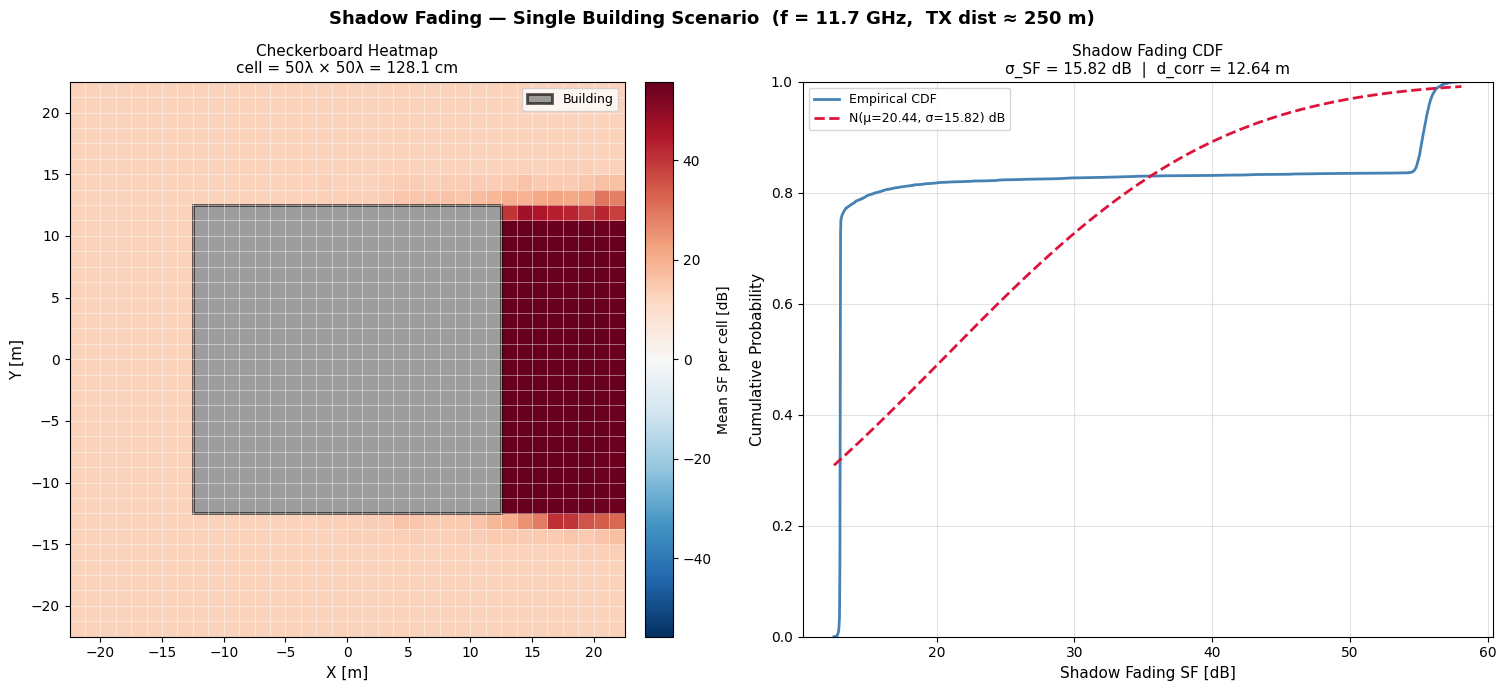

Figure saved → ./rician_building_sf_heatmap.png


In [80]:
# ─── Shadow Fading: Checkerboard Heatmap + CDF ──────────────────────────────

from scipy.stats        import binned_statistic_2d as _bin2d
from scipy.stats        import norm                 as _norm
from matplotlib.patches import Rectangle            as _Rect

rx_x_hm = np.array(nominal_rx_positions)[:, 0]
rx_y_hm = np.array(nominal_rx_positions)[:, 1]

# ── Grid: one cell = WINDOW_WAVELENGTHS × WINDOW_WAVELENGTHS ─────────────
HEATMAP_WAVELENGTHS = WINDOW_WAVELENGTHS          # change here to explore other scales
CELL_SIZE           = HEATMAP_WAVELENGTHS * LAMBDA_C   # [m]

x_min, x_max = rx_x_hm.min(), rx_x_hm.max()
y_min, y_max = rx_y_hm.min(), rx_y_hm.max()
n_bins_x = max(2, int(np.ceil((x_max - x_min) / CELL_SIZE)))
n_bins_y = max(2, int(np.ceil((y_max - y_min) / CELL_SIZE)))
x_edges  = np.linspace(x_min, x_max, n_bins_x + 1)
y_edges  = np.linspace(y_min, y_max, n_bins_y + 1)

sf_grid, _, _, _ = _bin2d(
    x=rx_x_hm, y=rx_y_hm, values=SF_dB,
    statistic='mean', bins=[x_edges, y_edges]
)
count_grid, _, _, _ = _bin2d(
    x=rx_x_hm, y=rx_y_hm, values=SF_dB,
    statistic='count', bins=[x_edges, y_edges]
)
sf_grid    = np.where(count_grid.T > 0, sf_grid.T, np.nan)   # mask empty cells
count_grid = count_grid.T

vmax_hm = float(np.nanpercentile(np.abs(sf_grid), 95))

print(f'Grid: {n_bins_x} × {n_bins_y} cells,  cell size = {CELL_SIZE*100:.2f} cm ({HEATMAP_WAVELENGTHS}λ)')
print(f'Occupied: {int((count_grid > 0).sum())} cells  |  '
      f'mean {count_grid[count_grid>0].mean():.1f} positions/cell')

# ── Figure: two panels ────────────────────────────────────────────────────
fig, (ax_hm, ax_cdf) = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(
    f'Shadow Fading — Single Building Scenario  '
    f'(f = {FREQUENCY/1e9:.1f} GHz,  TX dist ≈ {TX_DISTANCE:.0f} m)',
    fontsize=13, fontweight='bold'
)

# ══ LEFT: checkerboard heatmap ═══════════════════════════════════════════
img = ax_hm.imshow(
    sf_grid,
    origin        = 'lower',
    extent        = [x_min, x_max, y_min, y_max],
    cmap          = 'RdBu_r',
    vmin          = -vmax_hm,
    vmax          =  vmax_hm,
    aspect        = 'equal',
    interpolation = 'nearest',    # flat blocks → explicit checkerboard look
)
cbar = plt.colorbar(img, ax=ax_hm, fraction=0.046, pad=0.03)
cbar.set_label('Mean SF per cell [dB]', fontsize=10)

# grid lines at cell boundaries
for xe in x_edges:
    ax_hm.axvline(xe, color='white', linewidth=0.5, alpha=0.6)
for ye in y_edges:
    ax_hm.axhline(ye, color='white', linewidth=0.5, alpha=0.6)

# building footprint
ax_hm.add_patch(_Rect(
    (BUILDING_CENTER_X - BUILDING_DEPTH/2, BUILDING_CENTER_Y - BUILDING_WIDTH/2),
    BUILDING_DEPTH, BUILDING_WIDTH,
    linewidth=2, edgecolor='black', facecolor='dimgrey', alpha=0.65,
    label='Building'
))

# TX marker (only shown if it falls within the plot extent)
if x_min <= TX_POS[0] <= x_max and y_min <= TX_POS[1] <= y_max:
    ax_hm.plot(TX_POS[0], TX_POS[1], '*', color='gold',
               markersize=16, markeredgecolor='k', zorder=5, label='TX')

ax_hm.set_xlabel('X [m]', fontsize=11)
ax_hm.set_ylabel('Y [m]', fontsize=11)
ax_hm.set_title(
    f'Checkerboard Heatmap\n'
    f'cell = {HEATMAP_WAVELENGTHS}λ × {HEATMAP_WAVELENGTHS}λ = {CELL_SIZE*100:.1f} cm',
    fontsize=11
)
ax_hm.legend(loc='upper right', fontsize=9)

# ══ RIGHT: empirical CDF + Gaussian fit ══════════════════════════════════
sf_sorted = np.sort(SF_dB)
cdf_emp   = np.arange(1, len(sf_sorted) + 1) / len(sf_sorted)

ax_cdf.plot(sf_sorted, cdf_emp,
            color='steelblue', linewidth=2, label='Empirical CDF')

# Gaussian (log-normal in dB) fit using mu_SF / sigma_SF from §1.5
x_fit = np.linspace(float(SF_dB.min()), float(SF_dB.max()), 500)
ax_cdf.plot(x_fit, _norm.cdf(x_fit, loc=mu_SF, scale=sigma_SF),
            color='crimson', linewidth=2, linestyle='--',
            label=f'N(μ={mu_SF:.2f}, σ={sigma_SF:.2f}) dB')

# # reference lines
# ax_cdf.axvline(mu_SF,   color='k',      linestyle=':',  linewidth=1.2,
#                label=f'μ_SF = {mu_SF:.2f} dB')
# ax_cdf.axvline(mu_SF + sigma_SF, color='grey', linestyle=':', linewidth=1.0,
#                label=f'μ ± σ  (σ = {sigma_SF:.2f} dB)')
# ax_cdf.axvline(mu_SF - sigma_SF, color='grey', linestyle=':', linewidth=1.0)
# ax_cdf.axhline(0.5, color='dimgrey', linewidth=0.8, linestyle='-')

ax_cdf.set_xlabel('Shadow Fading SF [dB]', fontsize=11)
ax_cdf.set_ylabel('Cumulative Probability', fontsize=11)
ax_cdf.set_title(
    f'Shadow Fading CDF\n'
    f'σ_SF = {sigma_SF:.2f} dB  |  d_corr = {d_corr_m:.2f} m',
    fontsize=11
)
ax_cdf.set_ylim(0, 1)
ax_cdf.legend(fontsize=9)
ax_cdf.grid(True, alpha=0.35)

plt.tight_layout()
hm_path = './rician_building_sf_heatmap.png'
plt.savefig(hm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved → {hm_path}')
